# Laboratorium 04 — Splotowe sieci neuronowe (CNN)



## 0. Instalacja zależności

In [ ]:
!pip install torch torchvision matplotlib pandas tabulate

## Dane CIFAR-10 z Dysku Google



In [1]:
import os, glob, tarfile, hashlib

USE_DRIVE  = True
DRIVE_DIR  = "/content/drive/MyDrive/CIFAR10"
DATA_ROOT  = "/content/data"

# Wartości referencyjne oryginalnego archiwum CIFAR-10 (python version)
CIFAR_MD5  = "c58f30108f718f92721af3b95e74349a"
CIFAR_SIZE = 170498071

def prepare_cifar_from_drive(drive_dir, root, md5=CIFAR_MD5, size=CIFAR_SIZE):
    """Rozpakowuje CIFAR-10 z Dysku do `root`. Zwraca True, gdy dane są gotowe."""
    batches = os.path.join(root, "cifar-10-batches-py")
    if os.path.exists(os.path.join(batches, "test_batch")):
        print("Dane już rozpakowane w", batches); return True
    if os.path.isfile(drive_dir):
        cands = [drive_dir]
    else:
        cands = sorted(p for p in glob.glob(os.path.join(drive_dir, "cifar-10-python*")) if os.path.isfile(p))
    if not cands:
        print(f"Nie znaleziono pliku cifar-10-python*.tar.gz w: {drive_dir}"); return False
    path = cands[0]; got = os.path.getsize(path)
    print(f"Znaleziono: {path} ({got/1e6:.1f} MB)")
    if size is not None and got != size:
        print(f"Rozmiar się nie zgadza (oczekiwano {size/1e6:.1f} MB) — plik niekompletny."); return False
    if md5 is not None:
        h = hashlib.md5()
        with open(path, "rb") as f:
            for chunk in iter(lambda: f.read(1 << 20), b""): h.update(chunk)
        if h.hexdigest() != md5:
            print("Suma MD5 się nie zgadza — plik uszkodzony."); return False
    os.makedirs(root, exist_ok=True)
    try:
        with tarfile.open(path, "r:gz") as tar:
            try:    tar.extractall(root, filter="data")
            except TypeError: tar.extractall(root)
    except (tarfile.TarError, EOFError, OSError) as e:
        print("Błąd rozpakowywania:", e); return False
    ok = os.path.exists(os.path.join(batches, "test_batch"))
    print("Rozpakowano do", batches if ok else "(brak oczekiwanej struktury folderów)")
    return ok

DRIVE_OK = False
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_OK = True
    except ImportError:
        print("To nie jest Colab — pomijam montowanie Dysku.")

CIFAR_READY = prepare_cifar_from_drive(DRIVE_DIR, DATA_ROOT) if DRIVE_OK else False
if not CIFAR_READY:
    print("-> Dane zostaną pobrane z internetu przez torchvision (ok. 170 MB).")

Mounted at /content/drive
Znaleziono: /content/drive/MyDrive/CIFAR10/cifar-10-python.tar.gz (170.5 MB)
Rozpakowano do /content/data/cifar-10-batches-py


## 1. Importy, urządzenie i konfiguracja eksperymentu

Wszystkie parametry eksperymentu są w słowniku `CFG`. Oba modele używają tej samej konfiguracji, więc porównanie jest uczciwe .



Komórka tworzy też folder `RESULTS_DIR` na wyniki i zapisuje do niego konfigurację oraz nazwę GPU.

In [2]:
import copy, math, time, json, shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
from IPython.display import display

CFG = {
    "epochs": 10,        # budżet epok, ten sam dla obu modeli
    "lr": 1e-3,          # learning rate (Adam)
    "batch_size": 128,
    "n_val": 5000,       # rozmiar zbioru walidacyjnego wydzielonego z treningu
    "augment": False,    # augmentacja tylko na zbiorze treningowym (rozdział 7)
    "seed": 42,
}

torch.manual_seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if device == "cuda" else "brak (CPU)"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
print("GPU:", GPU_NAME)

# Folder na wyniki (tabele i wykresy do sprawozdania)
RESULTS_DIR = os.path.join(DRIVE_DIR, "wyniki_lab04") if DRIVE_OK else "./wyniki_lab04"
os.makedirs(RESULTS_DIR, exist_ok=True)
def out(name): return os.path.join(RESULTS_DIR, name)
print("Wyniki zapisywane w:", os.path.abspath(RESULTS_DIR))

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

ENV = {"CFG": CFG, "GPU": GPU_NAME, "torch": torch.__version__, "torchvision": torchvision.__version__,
       "device": device, "optymalizator": "Adam"}
with open(out("00_konfiguracja.json"), "w", encoding="utf-8") as f:
    json.dump(ENV, f, ensure_ascii=False, indent=2)
display(pd.DataFrame({"wartość": {**CFG, "GPU": GPU_NAME, "optymalizator": "Adam"}}))

PyTorch: 2.11.0+cu130 | urządzenie: cuda
GPU: Tesla T4
Wyniki zapisywane w: /content/drive/MyDrive/CIFAR10/wyniki_lab04


,wartość
epochs,10
lr,0.001
batch_size,128
n_val,5000
augment,False
seed,42
GPU,Tesla T4
optymalizator,Adam


## 2. Dane: CIFAR-10 z podziałem trening / walidacja / test

CIFAR-10 to 60 000 kolorowych obrazów 32×32 w 10 klasach (3 kanały wejścia).

- **Trening** (45 000): na nim model uczy się wag.
- **Walidacja** (5 000, wydzielona z treningu): na niej wybieramy najlepszą epokę.
- **Test** (10 000): używamy go **jeden raz**, na końcu, do oceny wybranego modelu.

Zbiór treningowy jest wczytany dwukrotnie: z augmentacją (do uczenia) i bez augmentacji (do walidacji). Podział indeksów jest losowany ze stałym ziarnem, więc jest taki sam dla obu modeli.



In [3]:
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

# download=True działa jako zabezpieczenie: gdy dane są już w DATA_ROOT, nic się nie pobiera
train_full_aug  = torchvision.datasets.CIFAR10(DATA_ROOT, train=True,  download=True, transform=tf_train)
train_full_eval = torchvision.datasets.CIFAR10(DATA_ROOT, train=True,  download=True, transform=tf_eval)
test_ds         = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=tf_eval)
classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]
train_ds = Subset(train_full_aug, train_idx)
val_ds   = Subset(train_full_eval, val_idx)

train_dl = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)
test_dl  = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)
print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: {len(test_ds)}")

Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000


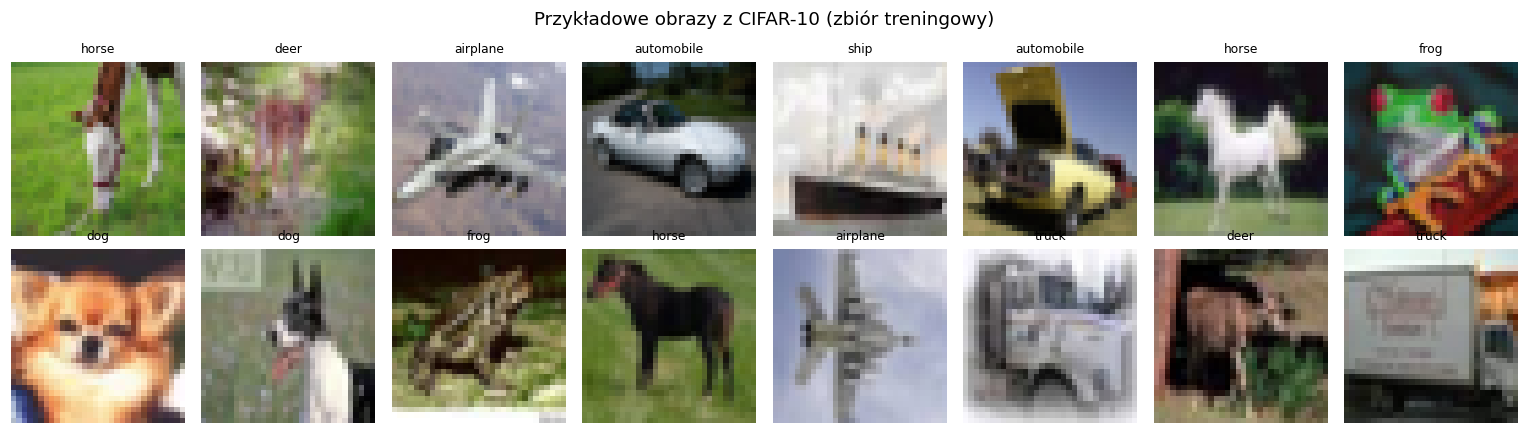

In [4]:
# Podgląd próbek; normalizację odwracamy, aby obraz miał naturalne kolory
mean_t = torch.tensor(mean).view(3, 1, 1); std_t = torch.tensor(std).view(3, 1, 1)
def denorm(img): return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_dl))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img)); ax.set_title(classes[lb], fontsize=8); ax.axis("off")
plt.suptitle("Przykładowe obrazy z CIFAR-10 (zbiór treningowy)")
plt.tight_layout(); plt.savefig(out("01_probki_cifar10.png")); plt.show()

## 3. Modele: MLP i SimpleCNN



In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x): return self.net(x)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),                                   # H, W zmniejszone o połowę
    )

class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, c1), block(c1, c2))  # 32x32 -> 8x8
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(c2*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),        # surowe logity, bez Softmax
        )
    def forward(self, x): return self.classifier(self.features(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print(f"MLP:                   {count_params(mlp_tmp):>10,}")
print(f"CNN część splotowa:    {count_params(cnn_tmp.features):>10,}")
print(f"CNN głowica:           {count_params(cnn_tmp.classifier):>10,}")
print(f"CNN razem:             {count_params(cnn_tmp):>10,}")

MLP:                    1,707,274
CNN część splotowa:        65,952
CNN głowica:            1,051,402
CNN razem:              1,117,354


## 4. Testy kontrolne przed treningiem



In [6]:
sanity = {}

# Test 1: przepływ kształtów przez SimpleCNN
x = torch.randn(4, 3, 32, 32)
for name, layer in cnn_tmp.features.named_children():
    x = layer(x); print("blok", name, tuple(x.shape))
logits_shape = tuple(cnn_tmp.classifier(x).shape)
print("logity", logits_shape)
sanity["Kształt wyjścia SimpleCNN dla N=4 (oczekiwany (4, 10))"] = str(logits_shape)

# Test 2: strata na starcie
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(train_dl))
for name, m in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    m = m.to(device).eval()
    with torch.no_grad():
        l0 = crit(m(xb.to(device)), yb.to(device)).item()
    print(f"{name}: strata na starcie {l0:.3f} (oczekiwane ok. {math.log(10):.3f})")
    sanity[f"Strata na starcie — {name} (oczekiwana ok. {math.log(10):.2f})"] = round(l0, 3)

# Test 3: przeuczenie jednej paczki (32 obrazy)
m = SimpleCNN().to(device); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
x32, y32 = xb[:32].to(device), yb[:32].to(device)
m.train()
for step in range(101):
    opt.zero_grad(); loss = crit(m(x32), y32); loss.backward(); opt.step()
    if step % 25 == 0: print(f"krok {step:3d} | strata {loss.item():.4f}")
    if step == 0:   sanity["Przeuczenie 1 paczki — strata w kroku 0"] = round(loss.item(), 4)
    if step == 100: sanity["Przeuczenie 1 paczki — strata w kroku 100"] = round(loss.item(), 4)

df_sanity = pd.DataFrame({"Test": list(sanity.keys()), "Wynik": list(sanity.values())})
display(df_sanity)
df_sanity.to_csv(out("02_testy_kontrolne.csv"), index=False)

blok 0 (4, 32, 16, 16)
blok 1 (4, 64, 8, 8)
logity (4, 10)
MLP: strata na starcie 2.309 (oczekiwane ok. 2.303)
CNN: strata na starcie 2.303 (oczekiwane ok. 2.303)
krok   0 | strata 2.3737
krok  25 | strata 0.0032
krok  50 | strata 0.0002
krok  75 | strata 0.0002
krok 100 | strata 0.0001


,Test,Wynik
0,Kształt wyjścia SimpleCNN dla N=4 (oczekiwany ...,"(4, 10)"
1,Strata na starcie — MLP (oczekiwana ok. 2.30),2.309
2,Strata na starcie — CNN (oczekiwana ok. 2.30),2.303
3,Przeuczenie 1 paczki — strata w kroku 0,2.3737
4,Przeuczenie 1 paczki — strata w kroku 100,0.0001


## 5. Funkcje treningu i ewaluacji

- `train_one_epoch` — jedna epoka uczenia; zwraca średnią stratę treningową.
- `evaluate` — strata i accuracy na podanym zbiorze, w trybie `model.eval()` i bez gradientów.
- `fit` — pełny trening. Po każdej epoce liczy stratę i accuracy na treningu i walidacji. Zapamiętuje wagi z epoki o **najwyższej accuracy walidacyjnej**. Zbioru testowego `fit` nie używa.

Czas uczenia (`train_time`) obejmuje tylko pętle treningowe. Czas ewaluacji jest mierzony osobno. Przed odczytem czasu wywołujemy `torch.cuda.synchronize()`, ponieważ obliczenia GPU są asynchroniczne.

Accuracy treningowa jest liczona osobnym przejściem przez zbiór treningowy w trybie `eval` (bez dropoutu). Dzięki temu przerwa train–walidacja jest mierzona tak samo dla obu zbiorów.

In [7]:
def sync():
    if device == "cuda": torch.cuda.synchronize()

def train_one_epoch(model, dl, opt, crit):
    model.train(); s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = crit(model(xb), yb); loss.backward(); opt.step()
        s += loss.item() * yb.size(0); n += yb.size(0)
    return s / n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval(); s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item(); n += yb.size(0)
    return s / n, c / n

# Ewaluacja na treningu: te same obrazy treningowe, ale bez augmentacji
train_eval_dl = DataLoader(Subset(train_full_eval, train_idx), batch_size=256,
                           shuffle=False, num_workers=2)

def fit(model, cfg=CFG):
    torch.manual_seed(cfg["seed"])
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1.0, "epoch": 0, "state": None}
    train_time = eval_time = 0.0
    for epoch in range(1, cfg["epochs"] + 1):
        sync(); t0 = time.time()
        train_one_epoch(model, train_dl, opt, crit)
        sync(); t1 = time.time()
        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync(); t2 = time.time()
        train_time += t1 - t0; eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]): hist[k].append(v)
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"  epoka {epoch:2d} | strata tr {tr_loss:.3f} wal {va_loss:.3f}"
              f" | acc tr {tr_acc*100:5.2f}% wal {va_acc*100:5.2f}%")
    model.load_state_dict(best["state"])      # przywracamy wagi z najlepszej epoki walidacyjnej
    return {"model": model, "hist": hist, "best": best,
            "train_time": train_time, "eval_time": eval_time}

## 6. Trening: MLP i SimpleCNN


Uruchomienie tej komórki ponownie tworzy **nowe** modele od początku.

In [8]:
print("== MLP ==")
res_mlp = fit(MLP())
print("\n== SimpleCNN ==")
res_cnn = fit(SimpleCNN())

== MLP ==
  epoka  1 | strata tr 1.448 wal 1.523 | acc tr 48.92% wal 46.26%
  epoka  2 | strata tr 1.346 wal 1.471 | acc tr 52.58% wal 48.88%
  epoka  3 | strata tr 1.210 wal 1.402 | acc tr 57.28% wal 51.70%
  epoka  4 | strata tr 1.155 wal 1.421 | acc tr 59.34% wal 50.54%
  epoka  5 | strata tr 1.049 wal 1.372 | acc tr 62.73% wal 52.70%
  epoka  6 | strata tr 0.952 wal 1.385 | acc tr 66.44% wal 52.90%
  epoka  7 | strata tr 0.886 wal 1.417 | acc tr 68.70% wal 53.50%
  epoka  8 | strata tr 0.836 wal 1.464 | acc tr 70.59% wal 53.54%
  epoka  9 | strata tr 0.774 wal 1.532 | acc tr 72.58% wal 52.30%
  epoka 10 | strata tr 0.697 wal 1.569 | acc tr 75.43% wal 53.36%

== SimpleCNN ==
  epoka  1 | strata tr 0.991 wal 1.005 | acc tr 64.41% wal 63.76%
  epoka  2 | strata tr 0.889 wal 0.940 | acc tr 68.95% wal 67.46%
  epoka  3 | strata tr 0.660 wal 0.739 | acc tr 76.56% wal 74.34%
  epoka  4 | strata tr 0.611 wal 0.729 | acc tr 78.41% wal 74.38%
  epoka  5 | strata tr 0.595 wal 0.753 | acc tr 7

## 7. Końcowa ocena na zbiorze testowym i tabela wyników

Każdy model oceniamy **jeden raz**, z wagami z epoki o najwyższej accuracy walidacyjnej. Wyniku testowego nie używamy do wyboru epoki ani konfiguracji. Predykcje z tego jednego przejścia są zapamiętane i wykorzystane później (macierze pomyłek), więc zbiór testowy nie jest oceniany ponownie.



,Wskaźnik,MLP,SimpleCNN
0,Parametry — łącznie,1 707 274,1 117 354
1,Parametry — część splotowa (features),—,65 952
2,Parametry — głowica gęsta (classifier),—,1 051 402
3,Epoka wybrana na walidacji,8,10
4,Accuracy trening [%],70.59,90.54
5,Accuracy walidacja [%],53.54,80.40
6,Przerwa train–walidacja [p.p.],17.05,10.14
7,Strata walidacyjna,1.464,0.610
8,Accuracy test [%],52.03,79.83
9,Strata testowa,1.465,0.618


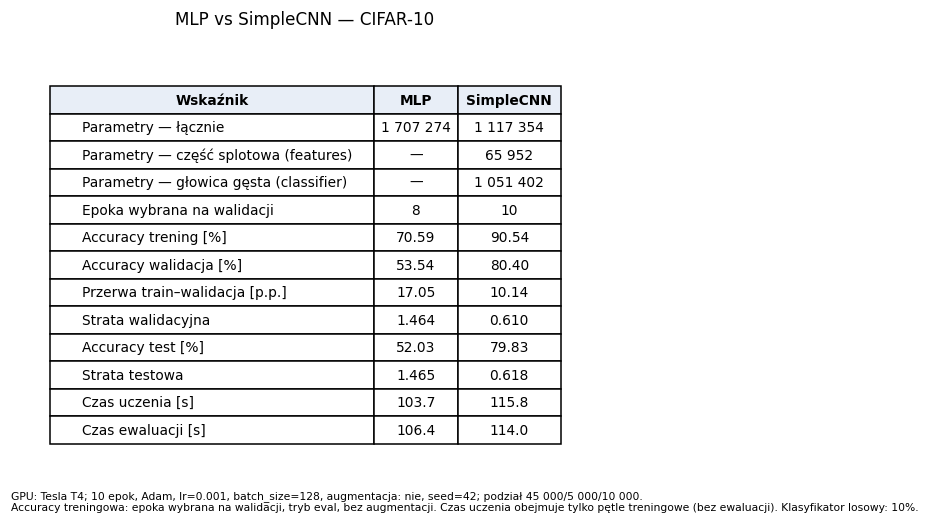

Accuracy test: MLP 52.03% | CNN 79.83% | różnica CNN − MLP: +27.80 p.p.
Względem klasyfikatora losowego (10%): MLP +42.03 p.p., CNN +69.83 p.p.
Parametry: CNN / MLP = 0.65
CNN: część splotowa to 5.9% parametrów, głowica 94.1%
Przerwa train–walidacja: MLP 17.05 p.p. | CNN 10.14 p.p.
Czas uczenia: MLP 103.7 s | CNN 115.8 s (CNN / MLP = 1.12)


In [10]:
@torch.no_grad()
def evaluate_test(model, dl, crit):
    """Jedno przejście po zbiorze testowym: strata, accuracy i predykcje."""
    model.eval(); s = n = 0; P, T = [], []
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0); n += yb.size(0)
        P.append(out.argmax(1).cpu()); T.append(yb.cpu())
    P = torch.cat(P).numpy(); T = torch.cat(T).numpy()
    return s / n, float((P == T).mean()), P, T

crit = nn.CrossEntropyLoss()
for name, r in [("MLP", res_mlp), ("SimpleCNN", res_cnn)]:
    if "test" not in r:                      # ocena testowa tylko raz dla każdego modelu
        tl, ta, P, T = evaluate_test(r["model"], test_dl, crit)
        r["test"] = {"loss": tl, "acc": ta, "pred": P, "true": T}

def summarize(name, r):
    m, h, b = r["model"], r["hist"], r["best"]; i = b["epoch"] - 1
    has_split = hasattr(m, "features")
    s = {"name": name, "params": count_params(m),
         "conv": count_params(m.features) if has_split else None,
         "head": count_params(m.classifier) if has_split else None,
         "best_epoch": b["epoch"], "train_acc": h["train_acc"][i] * 100, "val_acc": b["val_acc"] * 100,
         "val_loss": h["val_loss"][i], "test_acc": r["test"]["acc"] * 100, "test_loss": r["test"]["loss"],
         "train_time": r["train_time"], "eval_time": r["eval_time"]}
    s["gap"] = s["train_acc"] - s["val_acc"]
    return s

def fmt_int(x): return f"{x:,}".replace(",", " ")

def build_report_df(S):
    labels = ["Parametry — łącznie", "Parametry — część splotowa (features)",
              "Parametry — głowica gęsta (classifier)", "Epoka wybrana na walidacji",
              "Accuracy trening [%]", "Accuracy walidacja [%]", "Przerwa train–walidacja [p.p.]",
              "Strata walidacyjna", "Accuracy test [%]", "Strata testowa",
              "Czas uczenia [s]", "Czas ewaluacji [s]"]
    cols = {"Wskaźnik": labels}
    for s in S:
        cols[s["name"]] = [
            fmt_int(s["params"]),
            fmt_int(s["conv"]) if s["conv"] is not None else "—",
            fmt_int(s["head"]) if s["head"] is not None else "—",
            str(s["best_epoch"]), f"{s['train_acc']:.2f}", f"{s['val_acc']:.2f}", f"{s['gap']:.2f}",
            f"{s['val_loss']:.3f}", f"{s['test_acc']:.2f}", f"{s['test_loss']:.3f}",
            f"{s['train_time']:.1f}", f"{s['eval_time']:.1f}"]
    return pd.DataFrame(cols)

def save_table_png(df, path, title=None, footnote=None, col_w=2.3):
    fig, ax = plt.subplots(figsize=(max(6, col_w * len(df.columns)), 0.36 * len(df) + 1.0))
    ax.axis("off")
    tbl = ax.table(cellText=df.values, colLabels=list(df.columns), loc="center", cellLoc="center")
    tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.5)
    tbl.auto_set_column_width(list(range(len(df.columns))))
    for (row, col), cell in tbl.get_celld().items():
        if row == 0: cell.set_text_props(weight="bold"); cell.set_facecolor("#e8eef7")
        if col == 0 and row > 0: cell.set_text_props(ha="left"); cell.get_text().set_x(0.02)
    if title: ax.set_title(title, fontsize=11, pad=10)
    if footnote: ax.text(0.0, 0.0, footnote, fontsize=7, ha="left", va="top", transform=ax.transAxes)
    fig.savefig(path); plt.show()

S = [summarize("MLP", res_mlp), summarize("SimpleCNN", res_cnn)]
df_report = build_report_df(S)
display(df_report)

footnote = (f"GPU: {GPU_NAME}; {CFG['epochs']} epok, Adam, lr={CFG['lr']}, batch_size={CFG['batch_size']}, "
            f"augmentacja: {'tak' if CFG['augment'] else 'nie'}, seed={CFG['seed']}; podział 45 000/5 000/10 000.\n"
            "Accuracy treningowa: epoka wybrana na walidacji, tryb eval, bez augmentacji. "
            "Czas uczenia obejmuje tylko pętle treningowe (bez ewaluacji). Klasyfikator losowy: 10%.")
df_report.to_csv(out("03_tabela_wyniki.csv"), index=False, encoding="utf-8-sig")
try:
    with open(out("03_tabela_wyniki.md"), "w", encoding="utf-8") as f:
        f.write(df_report.to_markdown(index=False) + "\n\n" + footnote + "\n")
except ImportError:
    print("Brak biblioteki tabulate — pomijam eksport .md (pip install tabulate).")
save_table_png(df_report, out("03_tabela_wyniki.png"),
               title="MLP vs SimpleCNN — CIFAR-10", footnote=footnote)

# *do sprawozdania
mlp_s, cnn_s = S
print(f"Accuracy test: MLP {mlp_s['test_acc']:.2f}% | CNN {cnn_s['test_acc']:.2f}% "
      f"| różnica CNN − MLP: {cnn_s['test_acc'] - mlp_s['test_acc']:+.2f} p.p.")
print(f"Względem klasyfikatora losowego (10%): MLP {mlp_s['test_acc']-10:+.2f} p.p., CNN {cnn_s['test_acc']-10:+.2f} p.p.")
print(f"Parametry: CNN / MLP = {cnn_s['params'] / mlp_s['params']:.2f}")
print(f"CNN: część splotowa to {100*cnn_s['conv']/cnn_s['params']:.1f}% parametrów, "
      f"głowica {100*cnn_s['head']/cnn_s['params']:.1f}%")
print(f"Przerwa train–walidacja: MLP {mlp_s['gap']:.2f} p.p. | CNN {cnn_s['gap']:.2f} p.p.")
print(f"Czas uczenia: MLP {mlp_s['train_time']:.1f} s | CNN {cnn_s['train_time']:.1f} s "
      f"(CNN / MLP = {cnn_s['train_time'] / mlp_s['train_time']:.2f})")

## 8. Krzywe uczenia

Lewy wykres: strata, prawy: accuracy. Linie ciągłe to trening, przerywane to walidacja. Pionowa kropkowana linia oznacza epokę wybraną na walidacji.

 Duża i rosnąca przerwa między linią ciągłą a przerywaną oznacza przeuczenie.



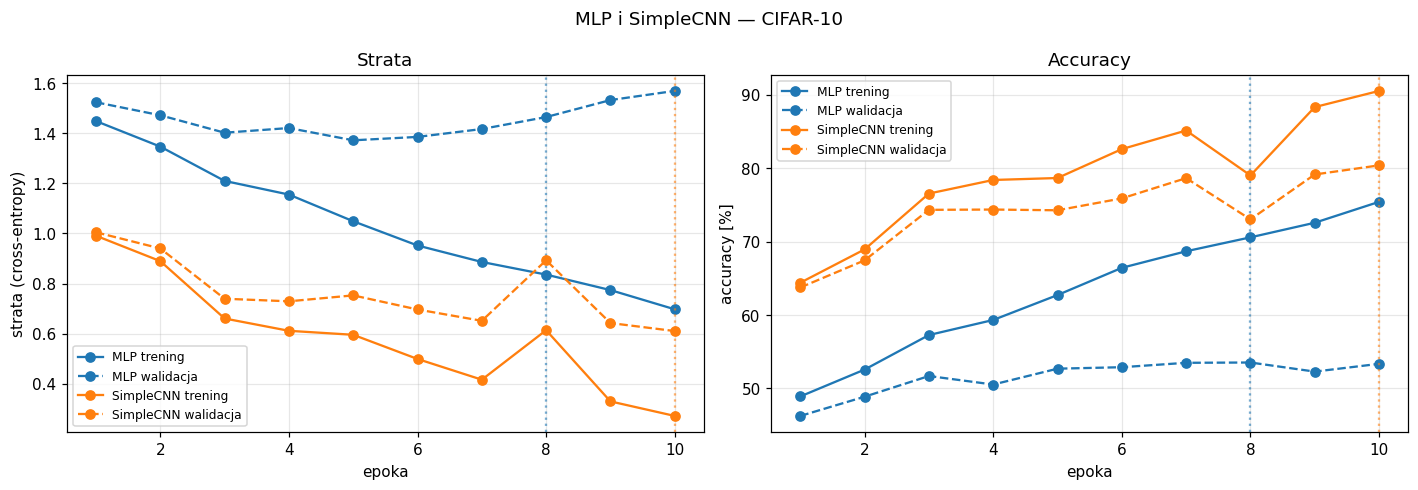

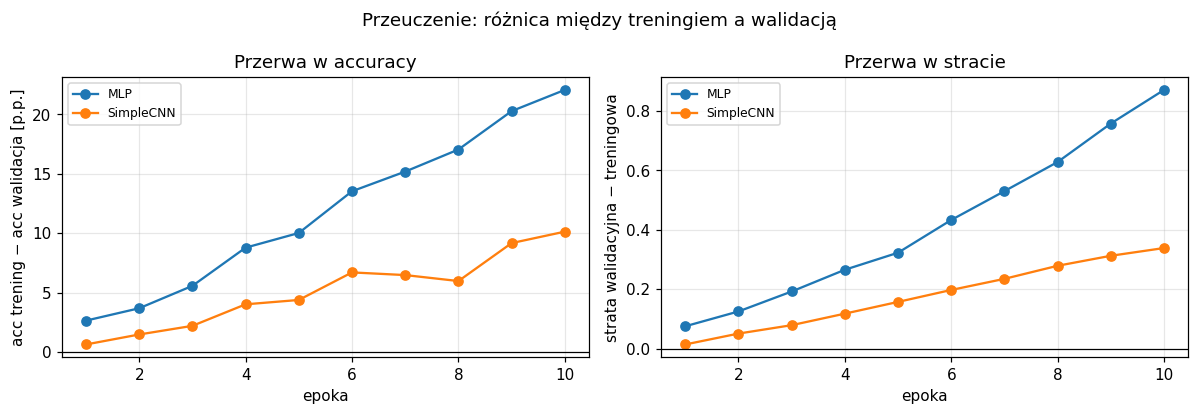


MLP:


,Epoka,Strata tr,Strata wal,Acc tr [%],Acc wal [%],Przerwa [p.p.]
0,1,1.4483,1.5234,48.92,46.26,2.66
1,2,1.3464,1.4715,52.58,48.88,3.70
2,3,1.2095,1.4018,57.28,51.70,5.58
3,4,1.1550,1.4205,59.34,50.54,8.80
4,5,1.0485,1.3715,62.73,52.70,10.03
5,6,0.9518,1.3851,66.44,52.90,13.54
6,7,0.8860,1.4165,68.70,53.50,15.20
7,8,0.8357,1.4643,70.59,53.54,17.05
8,9,0.7738,1.5321,72.58,52.30,20.28
9,10,0.6971,1.5686,75.43,53.36,22.07



SimpleCNN:


,Epoka,Strata tr,Strata wal,Acc tr [%],Acc wal [%],Przerwa [p.p.]
0,1,0.9907,1.0045,64.41,63.76,0.65
1,2,0.8894,0.9399,68.95,67.46,1.49
2,3,0.6605,0.7393,76.56,74.34,2.22
3,4,0.6113,0.7291,78.41,74.38,4.03
4,5,0.5954,0.7527,78.68,74.28,4.40
5,6,0.4989,0.6964,82.61,75.90,6.71
6,7,0.4162,0.6512,85.15,78.66,6.49
7,8,0.6137,0.8927,79.03,73.04,5.99
8,9,0.3296,0.6423,88.34,79.16,9.18
9,10,0.2716,0.6103,90.54,80.40,10.14


In [11]:
RUNS = [("MLP", res_mlp, "tab:blue"), ("SimpleCNN", res_cnn, "tab:orange")]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in RUNS:
    h = r["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "-o", color=color, label=f"{name} trening")
    ax2.plot(ep, [a*100 for a in h["val_acc"]], "--o", color=color, label=f"{name} walidacja")
    for ax in (ax1, ax2): ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)
ax1.set(xlabel="epoka", ylabel="strata (cross-entropy)", title="Strata")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
for ax in (ax1, ax2): ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("MLP i SimpleCNN — CIFAR-10"); plt.tight_layout()
plt.savefig(out("04_krzywe_uczenia.png")); plt.show()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for name, r, color in RUNS:
    h = r["hist"]; ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, [(t - v) * 100 for t, v in zip(h["train_acc"], h["val_acc"])], "-o", color=color, label=name)
    ax2.plot(ep, [v - t for t, v in zip(h["train_loss"], h["val_loss"])], "-o", color=color, label=name)
ax1.set(xlabel="epoka", ylabel="acc trening − acc walidacja [p.p.]", title="Przerwa w accuracy")
ax2.set(xlabel="epoka", ylabel="strata walidacyjna − treningowa", title="Przerwa w stracie")
for ax in (ax1, ax2): ax.axhline(0, color="k", lw=0.8); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("Przeuczenie: różnica między treningiem a walidacją"); plt.tight_layout()
plt.savefig(out("05_przerwa_train_walidacja.png")); plt.show()


def hist_df(name, r):
    h = r["hist"]; n = len(h["train_loss"])
    return pd.DataFrame({"Model": name, "Epoka": range(1, n + 1),
                         "Strata tr": np.round(h["train_loss"], 4), "Strata wal": np.round(h["val_loss"], 4),
                         "Acc tr [%]": np.round(np.array(h["train_acc"]) * 100, 2),
                         "Acc wal [%]": np.round(np.array(h["val_acc"]) * 100, 2),
                         "Przerwa [p.p.]": np.round((np.array(h["train_acc"]) - np.array(h["val_acc"])) * 100, 2)})
df_hist = pd.concat([hist_df(n, r) for n, r, _ in RUNS], ignore_index=True)
df_hist.to_csv(out("04_historia_uczenia.csv"), index=False, encoding="utf-8-sig")
for n, r, _ in RUNS:
    print(f"\n{n}:"); display(df_hist[df_hist["Model"] == n].drop(columns="Model").reset_index(drop=True))

## *Szczegóły klasyfikacji na zbiorze testowym

Accuracy dla poszczególnych klas oraz macierze pomyłek. Korzystają z predykcji zapamiętanych w sekcji 7, więc zbiór testowy nie jest oceniany ponownie. Pomagają opisać, które klasy sprawiają kłopot (np. kot–pies).

,MLP,SimpleCNN,różnica CNN − MLP
airplane,57.8,80.7,22.9
automobile,64.5,86.6,22.1
bird,34.0,67.6,33.6
cat,42.2,73.7,31.5
deer,42.7,80.1,37.4
dog,42.1,66.8,24.7
frog,52.7,85.1,32.4
horse,61.1,77.7,16.6
ship,67.5,92.4,24.9
truck,55.7,87.6,31.9


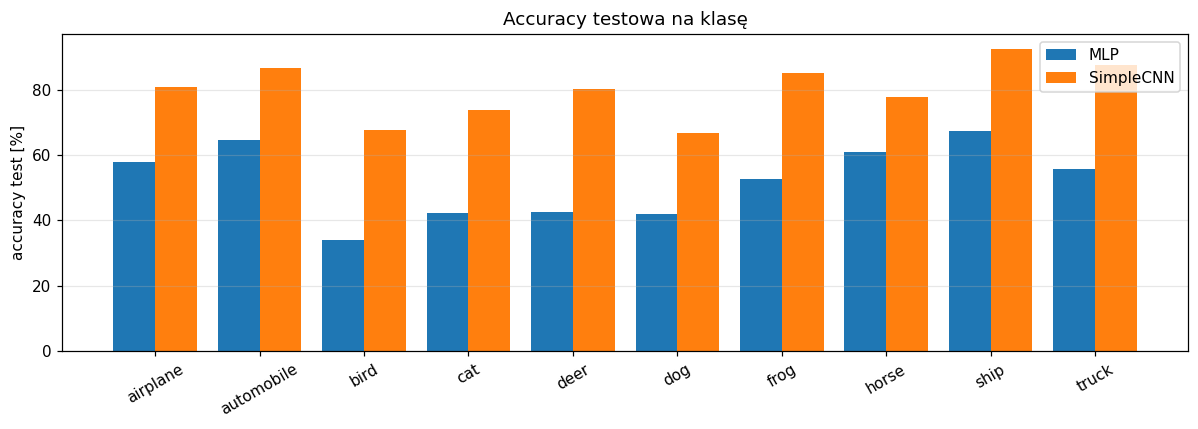

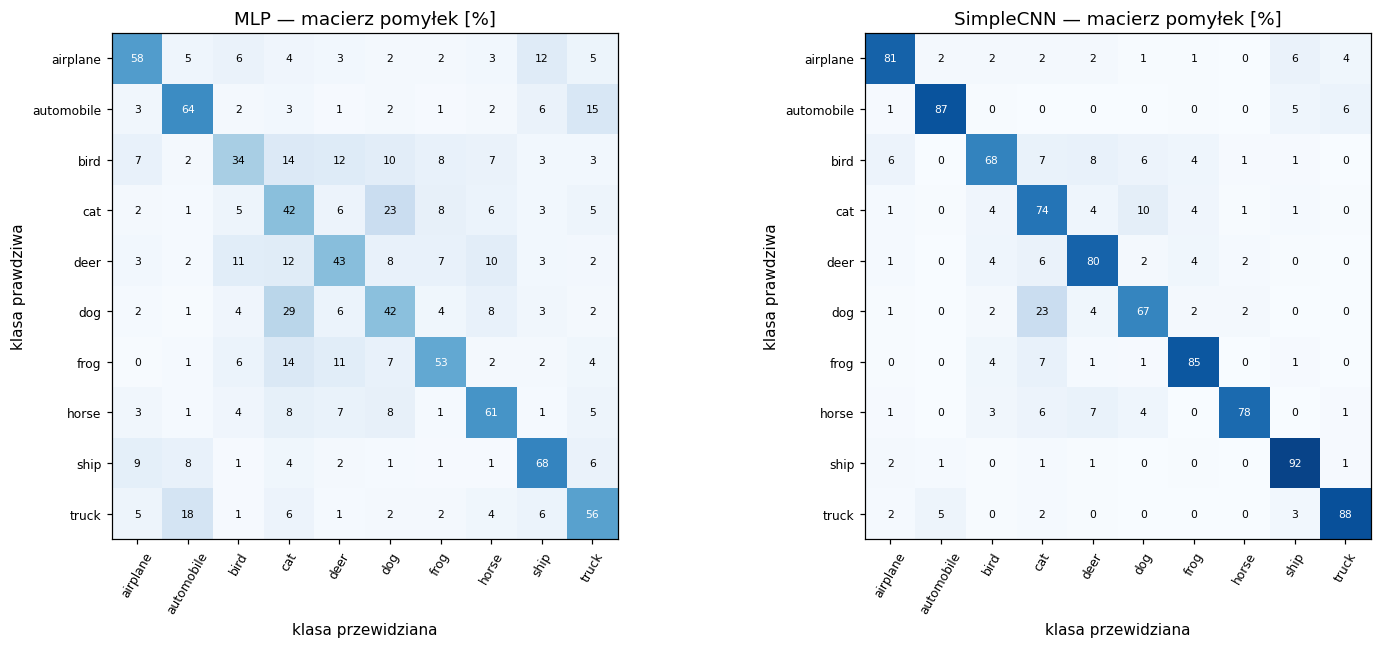

In [12]:
def confusion(true, pred, k=10):
    cm = np.zeros((k, k), dtype=int); np.add.at(cm, (true, pred), 1); return cm

cms = {n: confusion(r["test"]["true"], r["test"]["pred"]) for n, r, _ in RUNS}
per_class = pd.DataFrame({n: 100 * cm.diagonal() / cm.sum(1) for n, cm in cms.items()}, index=classes).round(2)
per_class["różnica CNN − MLP"] = (per_class["SimpleCNN"] - per_class["MLP"]).round(2)
display(per_class)
per_class.to_csv(out("07_accuracy_na_klase.csv"), encoding="utf-8-sig")

# Accuracy na klasę
fig, ax = plt.subplots(figsize=(11, 4)); w = 0.4; xs = np.arange(len(classes))
for j, (n, _, color) in enumerate(RUNS):
    ax.bar(xs + (j - 0.5) * w, per_class[n], w, label=n, color=color)
ax.set_xticks(xs); ax.set_xticklabels(classes, rotation=30); ax.set_ylabel("accuracy test [%]")
ax.set_title("Accuracy testowa na klasę"); ax.grid(axis="y", alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(out("07_accuracy_na_klase.png")); plt.show()

# Macierze pomyłek (znormalizowane po wierszach, w %)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (n, cm) in zip(axes, cms.items()):
    cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{cmn[i, j]*100:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(10)); ax.set_xticklabels(classes, rotation=60, fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(classes, fontsize=8)
    ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa"); ax.set_title(f"{n} — macierz pomyłek [%]")
plt.tight_layout(); plt.savefig(out("08_macierze_pomylek.png")); plt.show()

## 9. Mapy cech pierwszej i głębszej warstwy splotowej



mapy warstwy 1: (32, 32, 32) | mapy warstwy głębszej: (64, 16, 16)


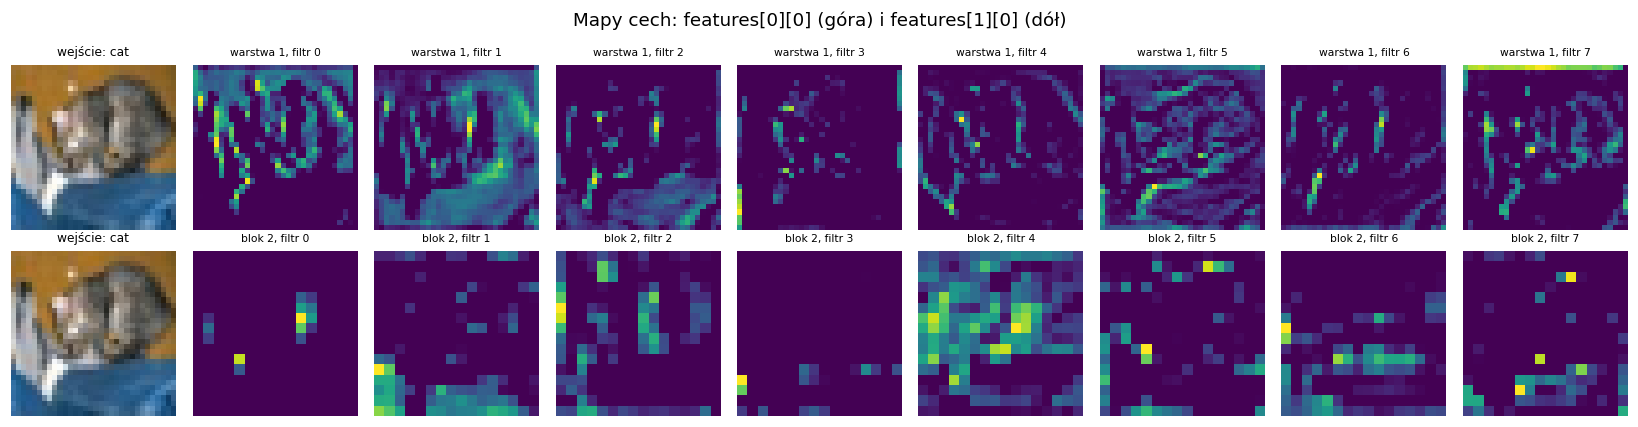

In [13]:
cnn = res_cnn["model"].eval()
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)                       # [3,32,32] -> [1,3,32,32]
with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()          # [32, 32, 32]
    after_block1 = cnn.features[0](x)                           # [1, 32, 16, 16]
    maps2 = torch.relu(cnn.features[1][0](after_block1))[0].cpu()  # [64, 16, 16]
print("mapy warstwy 1:", tuple(maps1.shape), "| mapy warstwy głębszej:", tuple(maps2.shape))

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for row, (maps, title) in enumerate([(maps1, "warstwa 1"), (maps2, "blok 2")]):
    axes[row, 0].imshow(denorm(img)); axes[row, 0].axis("off")
    axes[row, 0].set_title(f"wejście: {classes[label]}", fontsize=8)
    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis"); ax.axis("off")
        ax.set_title(f"{title}, filtr {i}", fontsize=7)
plt.suptitle("Mapy cech: features[0][0] (góra) i features[1][0] (dół)")
plt.tight_layout(); plt.savefig(out("09_mapy_cech.png")); plt.show()

## *Wpływ liczby filtrów i liczby bloków

Dwa niezależne eksperymenty (każdy zmienia **jeden** czynnik):

- **10a — liczba filtrów** w blokach: 16/32, 32/64, 64/128 (`SimpleCNN(c1, c2)`),
- **10b — liczba bloków**: 1, 2 i 3 bloki splotowe (`FlexCNN`). Wymiar wejścia głowicy jest wyliczany automatycznie z liczby bloków.

Konfiguracja bazowa (32/64, 2 bloki) **nie jest trenowana ponownie**, tylko brana z sekcji 6. Pozostałe warianty trenują się tą samą funkcją `fit` i z tą samą konfiguracją `CFG`. Porównujemy je wyłącznie na **walidacji**, zbiór testowy pozostaje nietknięty.

Domyślnie obie flagi są wyłączone, bo każdy eksperyment to dwa dodatkowe treningi (kilka minut na GPU). Aby uruchomić, flagę trzeba zmienić na `True`.


== Wpływ liczby filtrów w blokach: 16/32 ==
  epoka  1 | strata tr 1.019 wal 1.041 | acc tr 63.13% wal 61.78%
  epoka  2 | strata tr 0.856 wal 0.918 | acc tr 69.19% wal 67.24%
  epoka  3 | strata tr 0.719 wal 0.808 | acc tr 74.31% wal 71.24%
  epoka  4 | strata tr 0.654 wal 0.760 | acc tr 76.62% wal 72.26%
  epoka  5 | strata tr 0.575 wal 0.742 | acc tr 79.14% wal 73.74%
  epoka  6 | strata tr 0.493 wal 0.682 | acc tr 82.69% wal 76.84%
  epoka  7 | strata tr 0.512 wal 0.737 | acc tr 81.48% wal 74.62%
  epoka  8 | strata tr 0.437 wal 0.691 | acc tr 84.43% wal 76.00%
  epoka  9 | strata tr 0.407 wal 0.728 | acc tr 85.57% wal 76.38%
  epoka 10 | strata tr 0.363 wal 0.689 | acc tr 87.40% wal 76.78%

== Wpływ liczby filtrów w blokach: 64/128 ==
  epoka  1 | strata tr 1.162 wal 1.169 | acc tr 57.48% wal 57.02%
  epoka  2 | strata tr 0.868 wal 0.899 | acc tr 68.94% wal 68.68%
  epoka  3 | strata tr 0.798 wal 0.859 | acc tr 71.86% wal 69.66%
  epoka  4 | strata tr 0.661 wal 0.741 | acc tr 76.

,Konfiguracja,Parametry — łącznie,Parametry — splotowa,Parametry — głowica,Epoka,Acc walidacja [%],Przerwa tr–wal [p.p.],Czas uczenia [s]
0,16/32,543 962,16 848,527 114,6,76.84,5.85,120.5
1,32/64 (bazowa),1 117 354,65 952,1 051 402,10,80.40,10.14,115.8
2,64/128,2 360 906,260 928,2 099 978,10,80.62,7.74,135.2


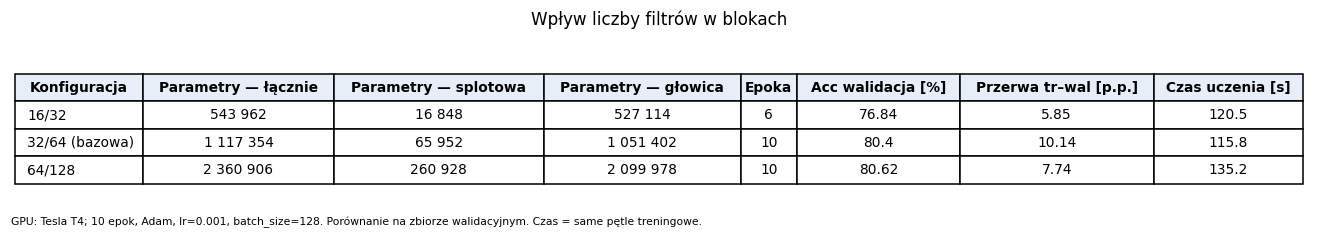

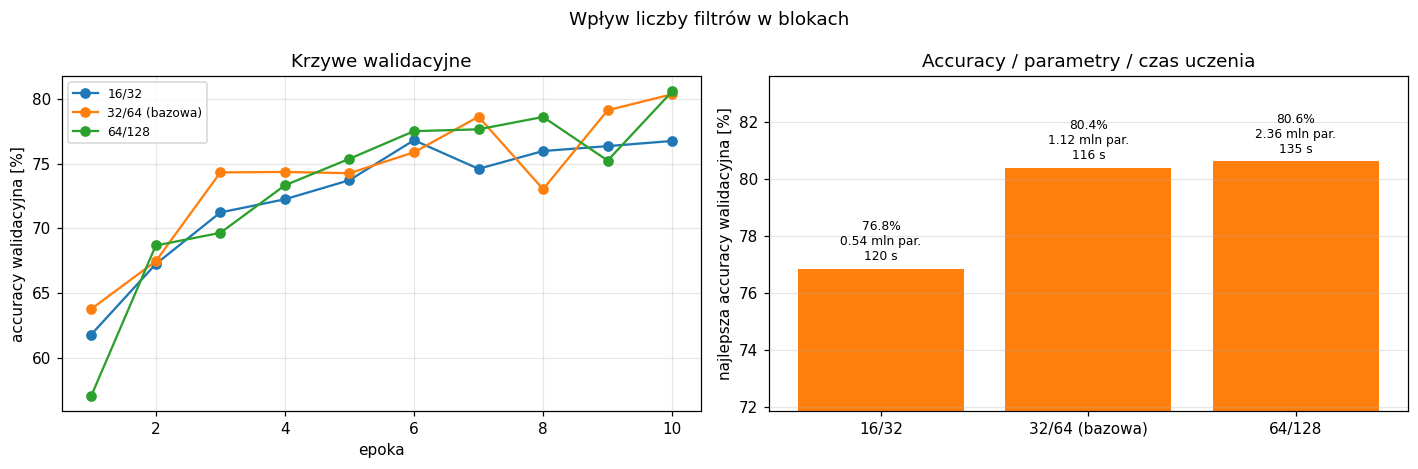


== Wpływ liczby bloków splotowych: 1 blok (32) ==
  epoka  1 | strata tr 1.167 wal 1.191 | acc tr 58.24% wal 58.32%
  epoka  2 | strata tr 0.971 wal 1.022 | acc tr 66.11% wal 64.28%
  epoka  3 | strata tr 0.842 wal 0.937 | acc tr 70.62% wal 67.20%
  epoka  4 | strata tr 0.753 wal 0.899 | acc tr 73.67% wal 68.02%
  epoka  5 | strata tr 0.683 wal 0.872 | acc tr 75.86% wal 69.18%
  epoka  6 | strata tr 0.652 wal 0.878 | acc tr 77.02% wal 68.84%
  epoka  7 | strata tr 0.585 wal 0.851 | acc tr 80.06% wal 70.24%
  epoka  8 | strata tr 0.540 wal 0.870 | acc tr 81.31% wal 70.38%
  epoka  9 | strata tr 0.483 wal 0.881 | acc tr 83.08% wal 70.18%
  epoka 10 | strata tr 0.417 wal 0.858 | acc tr 85.78% wal 71.44%

== Wpływ liczby bloków splotowych: 3 bloki (32/64/128) ==
  epoka  1 | strata tr 1.060 wal 1.071 | acc tr 61.78% wal 60.66%
  epoka  2 | strata tr 0.778 wal 0.845 | acc tr 72.53% wal 70.34%
  epoka  3 | strata tr 0.557 wal 0.654 | acc tr 80.43% wal 77.22%
  epoka  4 | strata tr 0.525 wal

,Konfiguracja,Parametry — łącznie,Parametry — splotowa,Parametry — głowica,Epoka,Acc walidacja [%],Przerwa tr–wal [p.p.],Czas uczenia [s]
0,1 blok (32),2 110 250,10 272,2 099 978,10,71.44,14.34,118.8
1,2 bloki (32/64) (bazowa),1 117 354,65 952,1 051 402,10,80.40,10.14,115.8
2,3 bloki (32/64/128),815 018,287 904,527 114,10,82.96,11.12,128.6


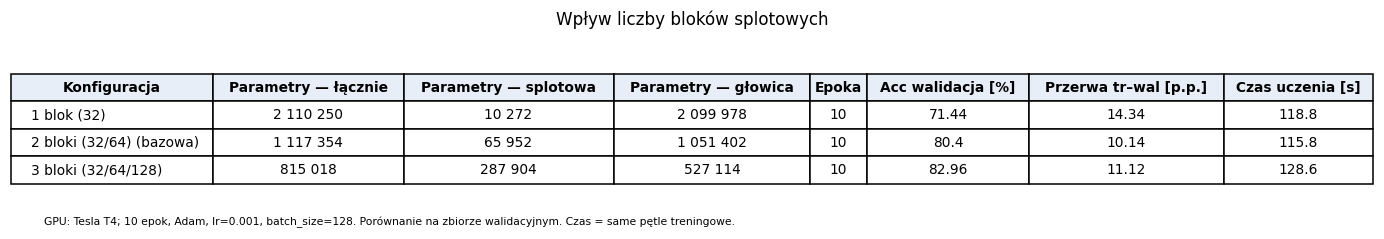

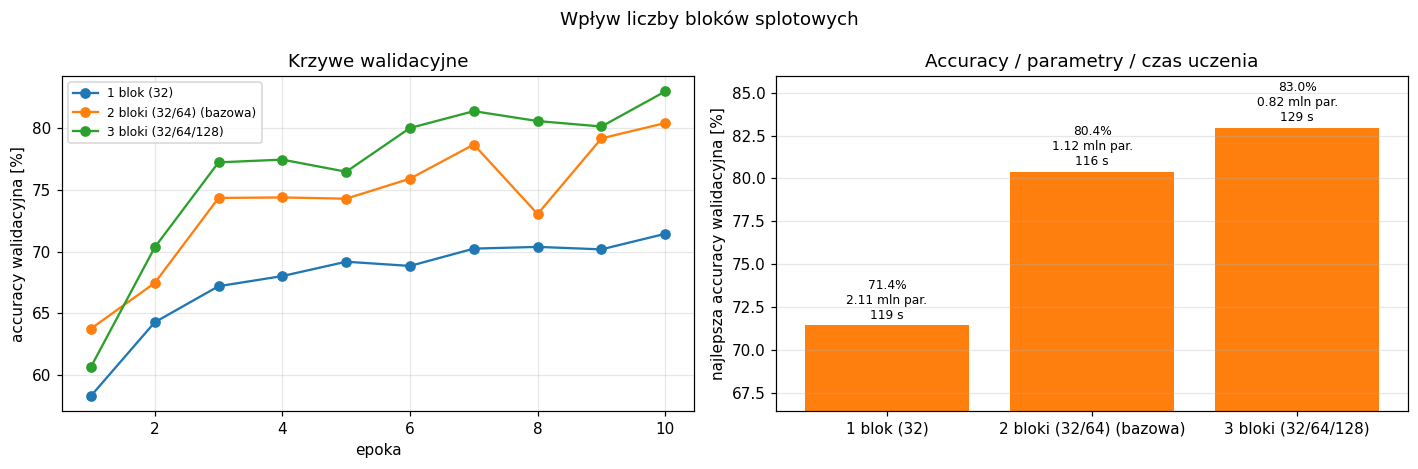

In [16]:
RUN_EXTRA_FILTERS = True     # 10a: 16/32, 32/64, 64/128 filtrów
RUN_EXTRA_DEPTH   = True     # 10b: 1, 2, 3 bloki

class FlexCNN(nn.Module):
    """CNN o dowolnej liczbie bloków; channels=(32, 64) odpowiada SimpleCNN(32, 64)."""
    def __init__(self, channels=(32, 64), n_classes=10):
        super().__init__()
        blocks, cin = [], 3
        for c in channels:
            blocks.append(block(cin, c)); cin = c
        self.features = nn.Sequential(*blocks)
        side = 32 // 2 ** len(channels)                      # każdy blok zmniejsza H i W dwukrotnie
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(cin * side * side, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x): return self.classifier(self.features(x))

assert count_params(FlexCNN((32, 64))) == count_params(SimpleCNN(32, 64)), "FlexCNN(32,64) powinien równać się SimpleCNN"

def run_extra(configs, title, tag):
    """configs: lista (etykieta, funkcja_budująca_model lub None dla konfiguracji bazowej)."""
    rows, curves = [], {}
    for label, builder in configs:
        if builder is None: r = res_cnn                       # konfiguracja bazowa: bez ponownego treningu
        else:
            print(f"\n== {title}: {label} =="); r = fit(builder())
        m, h, b = r["model"], r["hist"], r["best"]; i = b["epoch"] - 1
        rows.append({"Konfiguracja": label, "Parametry — łącznie": fmt_int(count_params(m)),
                     "Parametry — splotowa": fmt_int(count_params(m.features)),
                     "Parametry — głowica": fmt_int(count_params(m.classifier)),
                     "Epoka": b["epoch"], "Acc walidacja [%]": round(b["val_acc"] * 100, 2),
                     "Przerwa tr–wal [p.p.]": round((h["train_acc"][i] - b["val_acc"]) * 100, 2),
                     "Czas uczenia [s]": round(r["train_time"], 1),
                     "_p": count_params(m), "_va": b["val_acc"] * 100, "_t": r["train_time"]})
        curves[label] = [a * 100 for a in h["val_acc"]]
    df = pd.DataFrame(rows); show = df.drop(columns=["_p", "_va", "_t"])
    display(show); show.to_csv(out(f"{tag}_tabela.csv"), index=False, encoding="utf-8-sig")
    save_table_png(show, out(f"{tag}_tabela.png"), title=title, col_w=1.9,
                   footnote=f"GPU: {GPU_NAME}; {CFG['epochs']} epok, Adam, lr={CFG['lr']}, batch_size={CFG['batch_size']}. "
                            "Porównanie na zbiorze walidacyjnym. Czas = same pętle treningowe.")
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
    for label, c in curves.items(): ax1.plot(range(1, len(c) + 1), c, "-o", label=label)
    ax1.set(xlabel="epoka", ylabel="accuracy walidacyjna [%]", title="Krzywe walidacyjne"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)
    bars = ax2.bar(df["Konfiguracja"], df["_va"], color="tab:orange")
    lo = df["_va"].min(); ax2.set_ylim(max(0, lo - 5), df["_va"].max() + 3)
    for bar, (_, row) in zip(bars, df.iterrows()):
        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2,
                 f"{row['_va']:.1f}%\n{row['_p']/1e6:.2f} mln par.\n{row['_t']:.0f} s", ha="center", va="bottom", fontsize=8)
    ax2.set(ylabel="najlepsza accuracy walidacyjna [%]", title="Accuracy / parametry / czas uczenia"); ax2.grid(axis="y", alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(out(f"{tag}_wykres.png")); plt.show()
    return df

if RUN_EXTRA_FILTERS:
    df_filters = run_extra([("16/32", lambda: SimpleCNN(16, 32)),
                            ("32/64 (bazowa)", None),
                            ("64/128", lambda: SimpleCNN(64, 128))],
                           "Wpływ liczby filtrów w blokach", "10a_filtry")

if RUN_EXTRA_DEPTH:
    df_depth = run_extra([("1 blok (32)", lambda: FlexCNN((32,))),
                          ("2 bloki (32/64) (bazowa)", None),
                          ("3 bloki (32/64/128)", lambda: FlexCNN((32, 64, 128)))],
                         "Wpływ liczby bloków splotowych", "10b_bloki")

## Pobranie wyników



In [15]:
DOWNLOAD_ZIP = True

print("Zapisane pliki w", os.path.abspath(RESULTS_DIR))
for fn in sorted(os.listdir(RESULTS_DIR)):
    if fn.endswith(".zip"): continue
    print(f"  {fn:40s} {os.path.getsize(os.path.join(RESULTS_DIR, fn))/1024:8.1f} KB")

zip_base = "/content/wyniki_lab04" if os.path.isdir("/content") else "./wyniki_lab04"
zip_path = shutil.make_archive(zip_base, "zip", RESULTS_DIR)
print("\nArchiwum:", zip_path)
if DOWNLOAD_ZIP:
    try:
        from google.colab import files
        files.download(zip_path)
    except ImportError:
        pass

Zapisane pliki w /content/drive/MyDrive/CIFAR10/wyniki_lab04
  00_konfiguracja.json                          0.3 KB
  01_probki_cifar10.png                       109.3 KB
  02_testy_kontrolne.csv                        0.3 KB
  03_tabela_wyniki.csv                          0.5 KB
  03_tabela_wyniki.md                           1.2 KB
  03_tabela_wyniki.png                        154.0 KB
  04_historia_uczenia.csv                       0.8 KB
  04_krzywe_uczenia.png                       219.3 KB
  05_przerwa_train_walidacja.png              122.6 KB
  07_accuracy_na_klase.csv                      0.2 KB
  07_accuracy_na_klase.png                     69.9 KB
  08_macierze_pomylek.png                     138.6 KB
  09_mapy_cech.png                             80.8 KB

Archiwum: /content/wyniki_lab04.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>